# Analyze `optuna_search_lerm.py` results (LERM)

Optuna TPE search with patience-based early stopping for the LERM detector (Fisher-information transitions on a
recurrence network), run on CARC on the noisier data (60 train / 30 validation series; levels k1/k0p5/k0p25). Reads everything from `./results/`.
The KS counterpart lives in `../optuna_search_kstest/analyze_results.ipynb`, the ruptures one in `../optuna_search/analyze_results.ipynb`.

- Outer search space (Optuna): `m`, `target_density`, `w_size`, `w_incre`. Inner grid (25 cells, scored per trial, best cell kept):
  `block_size` x `(upper, lower)` bounds. Views: best config, convergence, hyperparameter-vs-score, inner surface, train vs. validation, noise effect.
- The held-out TEST split has not been scored yet (`evaluate_final_test()` in the search script). If `best_test_raw.csv` is missing, test columns are skipped.

In [1]:
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Image, display

METHODS_DIR = os.path.abspath("..")   # Methods/ -- for analyze_noise_effect.py
sys.path.insert(0, METHODS_DIR)
from analyze_noise_effect import load_merged, summarize_all_splits, NOISIER_DATA_DIR

LERM_RESULTS_DIR = "results"

with open(os.path.join(LERM_RESULTS_DIR, "best_params.json")) as f:
    lerm_best_params = json.load(f)
LERM_OBJECTIVE = lerm_best_params.get("objective", "warming")

lerm_trials_df = pd.read_csv(os.path.join(LERM_RESULTS_DIR, "optuna_trials.csv"))
lerm_conv_df = pd.read_csv(os.path.join(LERM_RESULTS_DIR, "optuna_convergence.csv"))
lerm_train_df = pd.read_csv(os.path.join(LERM_RESULTS_DIR, "best_train_raw.csv"))
lerm_val_df = pd.read_csv(os.path.join(LERM_RESULTS_DIR, "best_validation_raw.csv"))
lerm_surface_df = pd.read_csv(os.path.join(LERM_RESULTS_DIR, "best_inner_surface_train.csv"))
lerm_surface_val_df = pd.read_csv(os.path.join(LERM_RESULTS_DIR, "best_inner_surface_validation.csv"))

lerm_test_csv = os.path.join(LERM_RESULTS_DIR, "best_test_raw.csv")
lerm_test_df = pd.read_csv(lerm_test_csv) if os.path.exists(lerm_test_csv) else None
if lerm_test_df is None:
    print(f"{lerm_test_csv} not found -- test split not scored yet; test columns are skipped.")

print(f"objective optimized: f1_{LERM_OBJECTIVE}")
lerm_best_params

objective optimized: f1_warming


{'m': 5,
 'target_density': 0.021131651385277533,
 'w_size': 37,
 'w_incre': 11,
 'block_size': 1,
 'upper': 85.0,
 'lower': 15.0,
 'trial_number': 72,
 'objective': 'warming',
 'fixed': {'tau': 'auto',
  'eps': 1,
  'density_tolerance': 0.002,
  'amp': 10,
  'w': 50,
  'n_samples': 10000},
 'train_f1_all': 0.3273386876604517,
 'train_f1_warming': 0.24461931480844037,
 'train_f1_cooling': 0.20372230604541416,
 'train_mean_elapsed_s': 149.74097220332672,
 'run_metadata': {'wall_time_s': 48208.757678097114,
  'n_trials_this_run': 100,
  'n_trials_total': 100,
  'n_failed_total': 0,
  'patience': 50,
  'min_trials': 100,
  'min_delta': 0.01,
  'stopped_early': True,
  'stopped_at_trial': 99}}

## LERM: best configuration

The winning `(m, target_density, w_size, w_incre)` plus the inner-grid cell `(block_size, upper, lower)` and how the search ended.

In [2]:
LERM_PARAM_NAMES = ["m", "target_density", "w_size", "w_incre", "block_size", "upper", "lower"]
display(pd.Series({k: lerm_best_params.get(k) for k in LERM_PARAM_NAMES}, name="best value").to_frame())
print("fixed:", lerm_best_params.get("fixed"))

meta = lerm_best_params.get("run_metadata", {})
print(f"winning trial:      #{lerm_best_params['trial_number']}")
print(f"train f1_all / warming / cooling: {lerm_best_params['train_f1_all']:.3f} / "
      f"{lerm_best_params['train_f1_warming']:.3f} / {lerm_best_params['train_f1_cooling']:.3f}")
print(f"mean time per series: {lerm_best_params['train_mean_elapsed_s']:.1f} s")
print(f"trials run: {meta.get('n_trials_total')}  (failed: {meta.get('n_failed_total')})  "
      f"wall time: {meta.get('wall_time_s', float('nan'))/3600:.2f} h")
print(f"early stopping: patience={meta.get('patience')}, min_trials={meta.get('min_trials')}, "
      f"min_delta={meta.get('min_delta')}, stopped_early={meta.get('stopped_early')} "
      f"(at trial {meta.get('stopped_at_trial')})")

,best value
m,5.000000
target_density,0.021132
w_size,37.000000
w_incre,11.000000
block_size,1.000000
upper,85.000000
lower,15.000000


fixed: {'tau': 'auto', 'eps': 1, 'density_tolerance': 0.002, 'amp': 10, 'w': 50, 'n_samples': 10000}
winning trial:      #72
train f1_all / warming / cooling: 0.327 / 0.245 / 0.204
mean time per series: 149.7 s
trials run: 100  (failed: 0)  wall time: 13.39 h
early stopping: patience=50, min_trials=100, min_delta=0.01, stopped_early=True (at trial 99)


## LERM: trial states and convergence

trials total: 100
state
COMPLETE    100
Name: count, dtype: int64


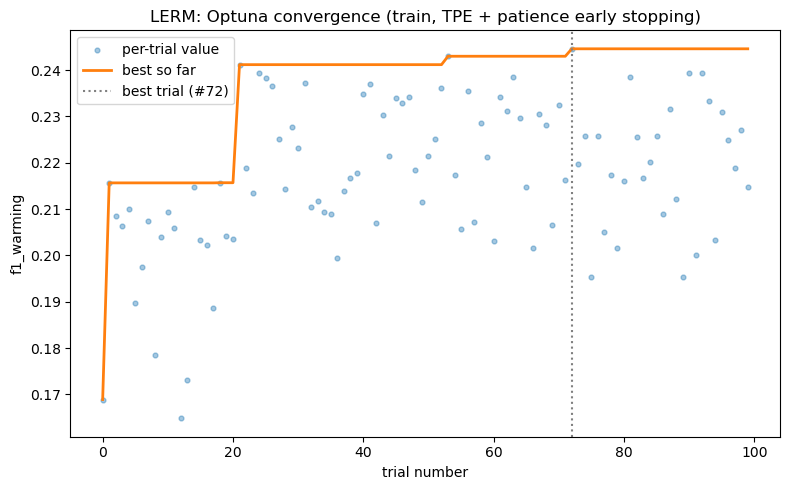

In [3]:
print(f"trials total: {len(lerm_trials_df)}")
print(lerm_trials_df['state'].value_counts())

complete = lerm_trials_df[lerm_trials_df['state'] == 'COMPLETE'].sort_values('number')
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(complete['number'], complete['value'], s=12, alpha=0.4, label='per-trial value')
ax.plot(lerm_conv_df['number'], lerm_conv_df['best_value_so_far'], color='C1', linewidth=2, label='best so far')
ax.axvline(lerm_best_params['trial_number'], color='gray', linestyle=':', label=f"best trial (#{lerm_best_params['trial_number']})")
ax.set_xlabel('trial number')
ax.set_ylabel(f"f1_{LERM_OBJECTIVE}")
ax.set_title('LERM: Optuna convergence (train, TPE + patience early stopping)')
ax.legend()
fig.tight_layout()
plt.show()

## LERM: search space (train, every trial Optuna tried)

Each panel plots one hyperparameter against the trial's train `f1_warming`; color = trial number. The dashed line marks the winning value.

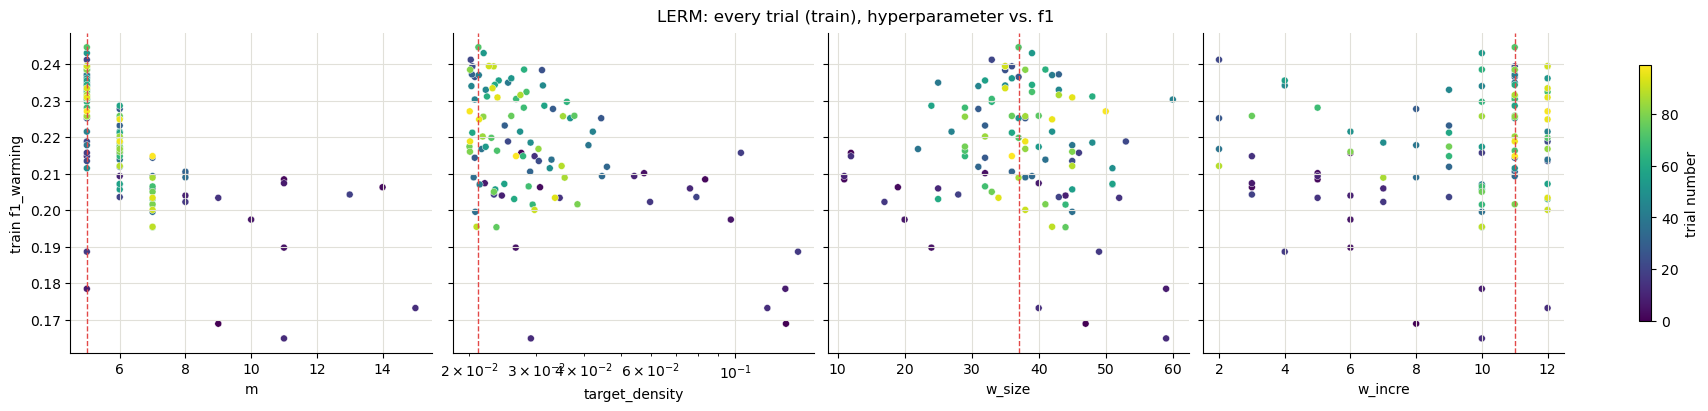

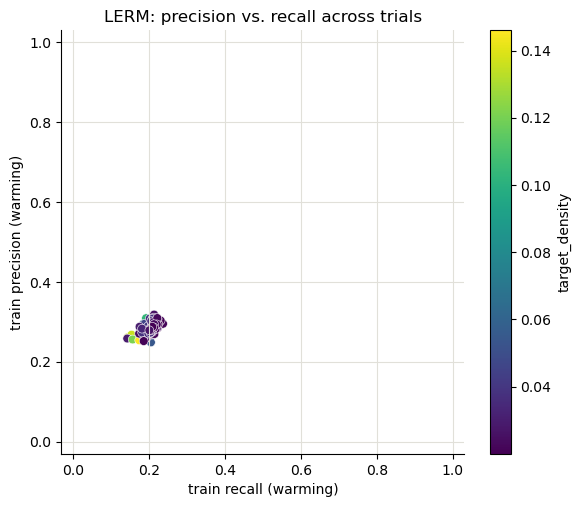

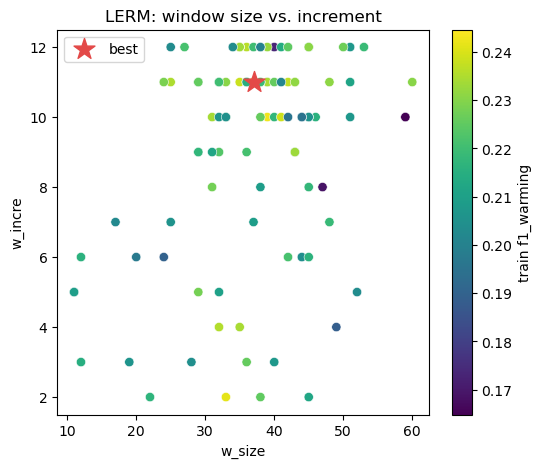

Top 10 trials:


,number,value,params_m,params_target_density,params_w_size,params_w_incre,user_attrs_best_block_size,user_attrs_best_upper,user_attrs_best_lower,user_attrs_mean_elapsed_s
72,72,0.244619,5,0.021132,37,11,1,85.0,15.0,149.740972
53,53,0.243012,5,0.021811,39,10,1,85.0,15.0,151.841805
21,21,0.241197,5,0.020176,33,2,5,85.0,15.0,212.437261
92,92,0.239459,5,0.022520,35,12,3,85.0,15.0,147.821139
24,24,0.239387,5,0.020381,36,11,1,90.0,10.0,149.476991
90,90,0.239370,5,0.023174,35,12,3,85.0,15.0,148.137391
63,63,0.238500,5,0.027860,41,10,1,85.0,15.0,153.112227
81,81,0.238450,5,0.020095,38,11,2,85.0,15.0,150.647646
25,25,0.238358,5,0.031047,35,11,2,85.0,15.0,150.088320
31,31,0.237179,5,0.020321,43,11,2,85.0,15.0,151.386886


In [4]:
lerm_params = [("params_m", "m"), ("params_target_density", "target_density"),
               ("params_w_size", "w_size"), ("params_w_incre", "w_incre")]

fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True, constrained_layout=True)
for ax, (col, name) in zip(axes, lerm_params):
    sc = ax.scatter(complete[col], complete['value'], c=complete['number'], cmap='viridis',
                    s=25, edgecolor='white', linewidth=0.3)
    ax.axvline(lerm_best_params[name], color='#e34948', linestyle='--', linewidth=1)
    ax.set_xlabel(name)
    if name == "target_density":
        ax.set_xscale("log")
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(f"train f1_{LERM_OBJECTIVE}")
fig.colorbar(sc, ax=axes.tolist(), label="trial number", shrink=0.8)
fig.suptitle("LERM: every trial (train), hyperparameter vs. f1")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(complete[f'user_attrs_mean_recall_{LERM_OBJECTIVE}'], complete[f'user_attrs_mean_precision_{LERM_OBJECTIVE}'],
                c=complete['params_target_density'], cmap='viridis', s=40, edgecolor='white', linewidth=0.4)
ax.set_xlabel(f"train recall ({LERM_OBJECTIVE})"); ax.set_ylabel(f"train precision ({LERM_OBJECTIVE})")
ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
ax.grid(color="#e1e0d9", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(sc, label="target_density")
ax.set_title("LERM: precision vs. recall across trials")
plt.show()

# pairwise: how do w_size and w_incre interact?
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(complete['params_w_size'], complete['params_w_incre'], c=complete['value'], cmap='viridis',
                s=45, edgecolor='white', linewidth=0.4)
ax.scatter(lerm_best_params['w_size'], lerm_best_params['w_incre'], marker='*', s=250, color='#e34948', label='best')
ax.set_xlabel('w_size'); ax.set_ylabel('w_incre'); ax.legend()
fig.colorbar(sc, label=f"train f1_{LERM_OBJECTIVE}")
ax.set_title("LERM: window size vs. increment")
plt.show()

print("Top 10 trials:")
cols = ['number', 'value', 'params_m', 'params_target_density', 'params_w_size', 'params_w_incre',
        'user_attrs_best_block_size', 'user_attrs_best_upper', 'user_attrs_best_lower', 'user_attrs_mean_elapsed_s']
display(complete.nlargest(10, 'value')[cols])

## LERM: inner grid (block_size x bounds) at the winning outer config

Each trial scores 25 inner cells and keeps the best; this shows all 25 cells for the winning trial (series-mean, train and validation).

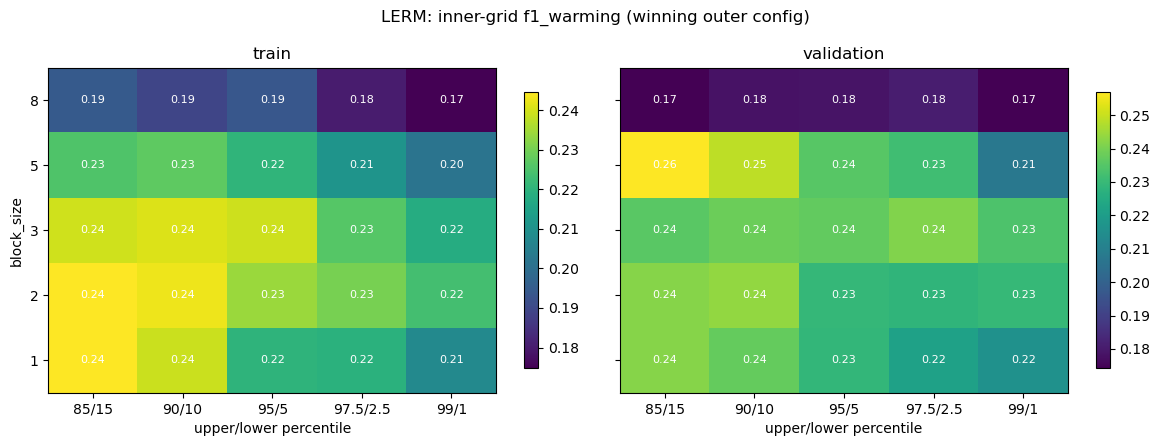

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, df) in zip(axes, [("train", lerm_surface_df), ("validation", lerm_surface_val_df)]):
    pv = df.pivot_table(index="block_size", columns="upper", values=f"f1_{LERM_OBJECTIVE}")
    im = ax.imshow(pv.values, cmap="viridis", aspect="auto", origin="lower")
    ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels([f"{u:g}/{100-u:g}" for u in pv.columns])
    ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index)
    ax.set_xlabel("upper/lower percentile"); ax.set_title(name)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            ax.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.85)
axes[0].set_ylabel("block_size")
fig.suptitle(f"LERM: inner-grid f1_{LERM_OBJECTIVE} (winning outer config)")
fig.tight_layout()
plt.show()

## LERM: winning config, train vs. validation vs. test

Per-series breakdown for the single winning config, split by direction (`all` / `warming` / `cooling`).

In [6]:
lerm_metric_cols = [c for c in lerm_train_df.columns if c.startswith(('precision_', 'recall_', 'f1_'))]
lerm_summary = {'train_mean': lerm_train_df[lerm_metric_cols].mean(), 'val_mean': lerm_val_df[lerm_metric_cols].mean()}
if lerm_test_df is not None:
    lerm_summary['test_mean'] = lerm_test_df[lerm_metric_cols].mean()
pd.DataFrame(lerm_summary)

,train_mean,val_mean,test_mean
precision_all,0.414029,0.403064,0.411307
recall_all,0.306752,0.292698,0.289659
f1_all,0.327339,0.317534,0.328748
precision_warming,0.303317,0.308753,0.305604
recall_warming,0.231102,0.222212,0.228532
f1_warming,0.244619,0.241922,0.254615
precision_cooling,0.265655,0.241245,0.268727
recall_cooling,0.187785,0.164338,0.175151
f1_cooling,0.203722,0.183248,0.204321


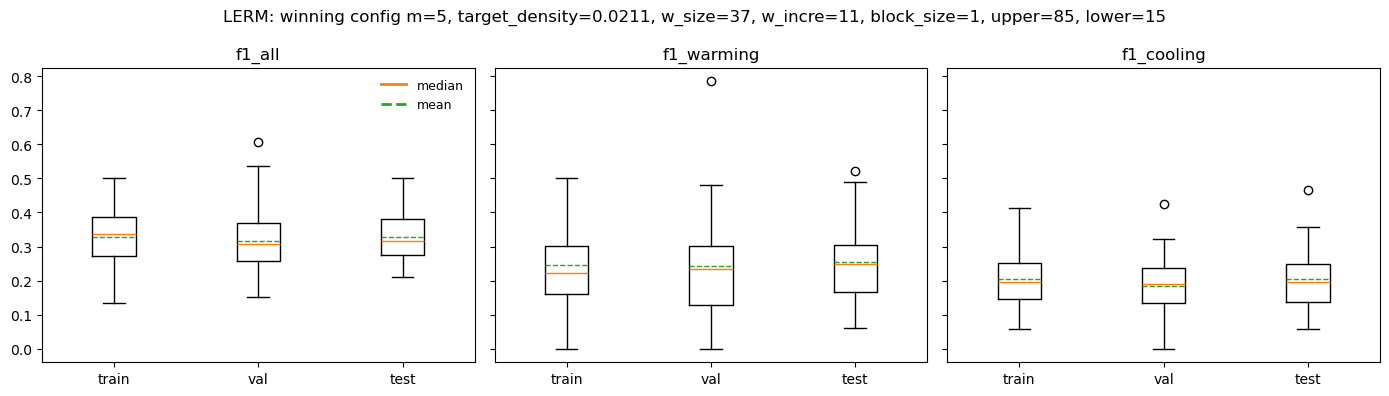

In [7]:
lerm_splits = [('train', lerm_train_df), ('val', lerm_val_df)] + ([('test', lerm_test_df)] if lerm_test_df is not None else [])

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, label in zip(axes, ('all', 'warming', 'cooling')):
    ax.boxplot([df[f'f1_{label}'].dropna() for _, df in lerm_splits],
               tick_labels=[name for name, _ in lerm_splits], showmeans=True, meanline=True)
    ax.set_title(f'f1_{label}')
axes[0].legend(handles=[Line2D([0], [0], color='C1', linewidth=2, label='median'),
                        Line2D([0], [0], color='C2', linewidth=2, linestyle='--', label='mean')],
               loc='upper right', frameon=False, fontsize=9)
fig.suptitle("LERM: winning config " + ", ".join(f"{k}={lerm_best_params[k]:.3g}" for k in LERM_PARAM_NAMES))
fig.tight_layout()
plt.show()

## LERM: noise-condition effect (test split, winning config)

How noise **color** (white/pink/red) and **level** change detection performance on the held-out TEST split only
(`analyze_noise_effect.py`, noisier data, levels k1/k0p5/k0p25). Needs `best_test_raw.csv` (see `evaluate_test_lerm.py` / `.slurm`, run on CARC).

In [8]:
LERM_METRICS = [f'precision_{LERM_OBJECTIVE}', f'recall_{LERM_OBJECTIVE}', f'f1_{LERM_OBJECTIVE}']
LERM_TEST_MERGED = load_merged(LERM_RESULTS_DIR, NOISIER_DATA_DIR, 'test')
if LERM_TEST_MERGED is None:
    print("best_test_raw.csv not found -- run evaluate_test_lerm.slurm on CARC, copy the csv into results/, then re-run from the top.")
else:
    for metric in LERM_METRICS:
        print(f"=== LERM test: {metric} by noise condition (sorted by mean) ===")
        print(summarize_all_splits({'test': LERM_TEST_MERGED}, metric).to_string(float_format=lambda x: f"{x:.3f}"))
        print()

=== LERM test: precision_warming by noise condition (sorted by mean) ===
             test            
             mean   std count
color level                  
white k1    0.456 0.055     4
pink  k1    0.454 0.150     3
red   k1    0.356 0.167     4
pink  k0p5  0.340 0.057     3
      k0p25 0.271 0.087     4
red   k0p5  0.243 0.080     3
white k0p5  0.243 0.032     3
      k0p25 0.201 0.110     3
red   k0p25 0.132 0.052     3

=== LERM test: recall_warming by noise condition (sorted by mean) ===
             test            
             mean   std count
color level                  
white k1    0.433 0.066     4
      k0p5  0.294 0.021     3
pink  k1    0.271 0.170     3
      k0p5  0.221 0.041     3
white k0p25 0.217 0.106     3
red   k1    0.204 0.141     4
pink  k0p25 0.182 0.028     4
red   k0p5  0.122 0.020     3
      k0p25 0.068 0.034     3

=== LERM test: f1_warming by noise condition (sorted by mean) ===
             test            
             mean   std count
color lev

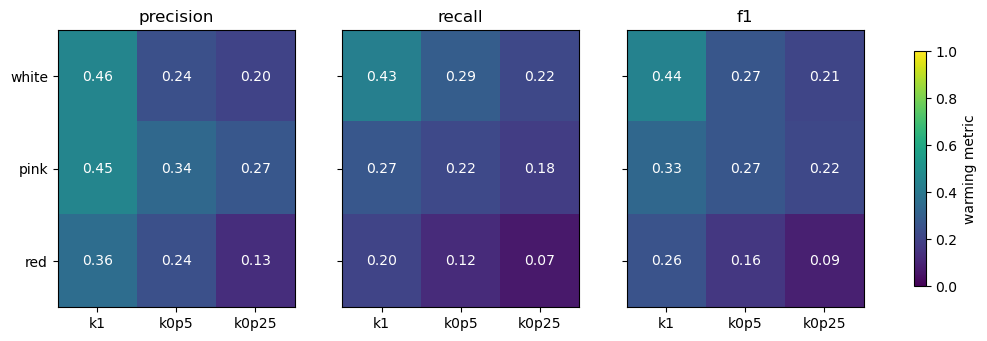

In [9]:
if LERM_TEST_MERGED is not None:
    colors = ["white", "pink", "red"]
    levels = ["k1", "k0p5", "k0p25"]   # clean -> noisy
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for ax, key in zip(axes, ["precision", "recall", "f1"]):
        pv = (LERM_TEST_MERGED.pivot_table(index="color", columns="level", values=f"{key}_{LERM_OBJECTIVE}", aggfunc="mean")
                              .reindex(index=colors, columns=levels))
        im = ax.imshow(pv.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(levels))); ax.set_xticklabels(levels)
        ax.set_yticks(range(len(colors))); ax.set_yticklabels(colors)
        ax.set_title(key)
        for i in range(pv.shape[0]):
            for j in range(pv.shape[1]):
                v = pv.values[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black")
    fig.colorbar(im, ax=axes.tolist(), shrink=0.85, label=f"{LERM_OBJECTIVE} metric")
    plt.show()

## LERM: why is F1 low?

Compared on the same noisier data, LERM (F1 warming ~0.24) is well below KS (~0.43). Three diagnostics:
detections vs. true events, timing accuracy vs. the +-0.5 kyr tolerance, and whether the search piled up at the edge of its ranges.

In [10]:
KS_DIR = os.path.join(METHODS_DIR, "optuna_search_kstest", "noisier_results")
ks_tr = pd.read_csv(os.path.join(KS_DIR, "best_train_raw.csv")); ks_va = pd.read_csv(os.path.join(KS_DIR, "best_validation_raw.csv"))
cols = ['precision_warming', 'recall_warming', 'f1_warming', 'precision_all', 'recall_all', 'f1_all', 'timing_mae_warming']
display(pd.DataFrame({'LERM train': lerm_train_df[cols].mean(), 'LERM val': lerm_val_df[cols].mean(),
                      'KS train': ks_tr[cols].mean(), 'KS val': ks_va[cols].mean()}).round(3))

d = np.load(os.path.join(NOISIER_DATA_DIR, "train.npz"))
n_true = np.mean([(np.diff(x) != 0).sum() for x in d['state_true']])
print(f"true transitions per train series: {n_true:.1f}  |  LERM detections per series: {lerm_train_df['n_detected'].mean():.1f}  "
      f"|  matched (all): {lerm_train_df['timing_n_matched_all'].mean():.1f}")
print(f"LERM timing MAE of matched warming events: {lerm_train_df['timing_mae_warming'].mean():.2f} kyr (tolerance 0.5)")

# Did the search pile up at the edge of its ranges?
edges = {"m": (5, 15), "w_size": (10, 60), "target_density": (0.02, 0.15)}
for k, (lo, hi) in edges.items():
    print(f"{k}: winner {lerm_best_params[k]:.3g}, range [{lo}, {hi}]")
top = complete.nlargest(10, 'value')
print("top-10 trials with m at its lower bound (5):", int((top['params_m'] == 5).sum()), "/ 10")
print("inner-grid winner (block_size=1 of {1,2,3,5,8}; bounds 85/15 of {85/15 ... 99/1}) is the first / loosest option on both axes.")

,LERM train,LERM val,KS train,KS val
precision_warming,0.303,0.309,0.484,0.364
recall_warming,0.231,0.222,0.606,0.512
f1_warming,0.245,0.242,0.430,0.377
precision_all,0.414,0.403,0.501,0.450
recall_all,0.307,0.293,0.632,0.561
f1_all,0.327,0.318,0.449,0.402
timing_mae_warming,0.235,0.289,0.157,0.162


true transitions per train series: 48.2  |  LERM detections per series: 33.6  |  matched (all): 13.7
LERM timing MAE of matched warming events: 0.24 kyr (tolerance 0.5)
m: winner 5, range [5, 15]
w_size: winner 37, range [10, 60]
target_density: winner 0.0211, range [0.02, 0.15]
top-10 trials with m at its lower bound (5): 10 / 10
inner-grid winner (block_size=1 of {1,2,3,5,8}; bounds 85/15 of {85/15 ... 99/1}) is the first / loosest option on both axes.


**Reading it:** recall is the problem (~0.22 vs. KS ~0.5-0.6): LERM finds only a fraction of the ~48 true transitions per series, and the ones it does
match are localized worse (MAE ~0.24 vs. ~0.16 kyr for KS). The winning config sits at the edge of every range it can hit -- lowest `m`,
smallest `block_size`, loosest threshold pair -- which means the search wanted to go further in that direction, so the ranges (not the optimizer)
are limiting the score. Also, warming/cooling labels come from a sign convention that was only ~83% correct when checked (see `_lerm_directions`),
which caps warming precision/recall even for correctly timed detections.

## LERM applied to real NGRIP data

The frozen LERM `best_params` (zero re-tuning) are applied to the NGRIP d18O record sliced to the DO-catalog window, in forward time
(same construction as the KS notebook), standardized like the synthetic series. Only **warming**-classified detections inside the labeled range are
scored against the 25 real DO warming events (Rasmussen 2014).

In [11]:
import ammonyte as amt
from ammonyte.utils.metrics import evaluate_detection
from ammonyte.core.transitions import DeterministicTransitions
sys.path.insert(0, os.path.abspath("."))
from optuna_search_lerm import _fisher_series, _lerm_directions, BOOT_W, BOOT_N_SAMPLES, TOLERANCE

AMMONYTE_DATA_DIR = os.path.join(os.path.dirname(amt.__file__), "data")
ngrip_series = amt.Series.from_csv(os.path.join(AMMONYTE_DATA_DIR, "NGRIP.csv"))
do_df = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "DO_onsets_Rasmussen2014.csv"), comment="#")
do_gt_age = np.sort(do_df["main25_kyr_b2k"].dropna().values.astype(float))

def to_forward_time(series):
    return amt.Series(time=-series.time[::-1], value=series.value[::-1],
                      time_name="time (forward)", time_unit="-kyr b2k",
                      value_name=series.value_name, value_unit=series.value_unit,
                      label=f"{series.label} (forward time)", verbose=False)

ngrip_win = to_forward_time(ngrip_series.slice([do_gt_age.min(), do_gt_age.max()]))
ngrip_std = ngrip_win.standardize()
do_gt_times = np.sort(-do_gt_age)
print(f"NGRIP window: {len(ngrip_std.time)} points; DO events: {len(do_gt_age)}")

Time axis values sorted in ascending order
Time axis values sorted in ascending order
NGRIP window: 5034 points; DO events: 25


In [12]:
import copy

def score_ngrip_lerm(series, gt_times, tolerance, label):
    fi = _fisher_series(series.time, series.value, int(lerm_best_params['m']), lerm_best_params['target_density'],
                        int(lerm_best_params['w_size']), int(lerm_best_params['w_incre']))
    smoothed = amt.utils.fisher.smooth_series(copy.deepcopy(fi), block_size=int(lerm_best_params['block_size']))
    transitions = smoothed.lerm_transitions(upper=lerm_best_params['upper'], lower=lerm_best_params['lower'],
                                            w=BOOT_W, n_samples=BOOT_N_SAMPLES)
    detected_all, dirs_all = _lerm_directions(transitions)
    in_range = (detected_all >= gt_times.min()) & (detected_all <= gt_times.max())
    detected, dirs = detected_all[in_range], dirs_all[in_range]
    detected_warming = detected[dirs == "warming"]
    print(f"--- {label}: {len(detected_all)} detected, {len(detected)} in range, {len(detected_warming)} warming (scored) ---")
    metrics = evaluate_detection(detected=detected_warming, ground_truth=gt_times, tolerance=tolerance)
    print(metrics)
    return detected_warming, detected, metrics

lerm_ngrip_det, lerm_ngrip_all, lerm_ngrip_metrics = score_ngrip_lerm(ngrip_std, do_gt_times, TOLERANCE, "LERM, standardized NGRIP")

--- LERM, standardized NGRIP: 30 detected, 30 in range, 17 warming (scored) ---
Detection Evaluation Metrics
Metrics calculated within tolerance = 0.5

Performance Scores:
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| Precision |  0.4118 |
+-----------+---------+
| Recall    |  0.28   |
+-----------+---------+
| F1 Score  |  0.3333 |
+-----------+---------+

Detection Counts:
+-----------------+---------+
| Category        |   Count |
+=================+=========+
| True Positives  |       7 |
+-----------------+---------+
| False Positives |      10 |
+-----------------+---------+
| False Negatives |      18 |
+-----------------+---------+

Summary:
  Detected: 17 | Ground Truth: 25



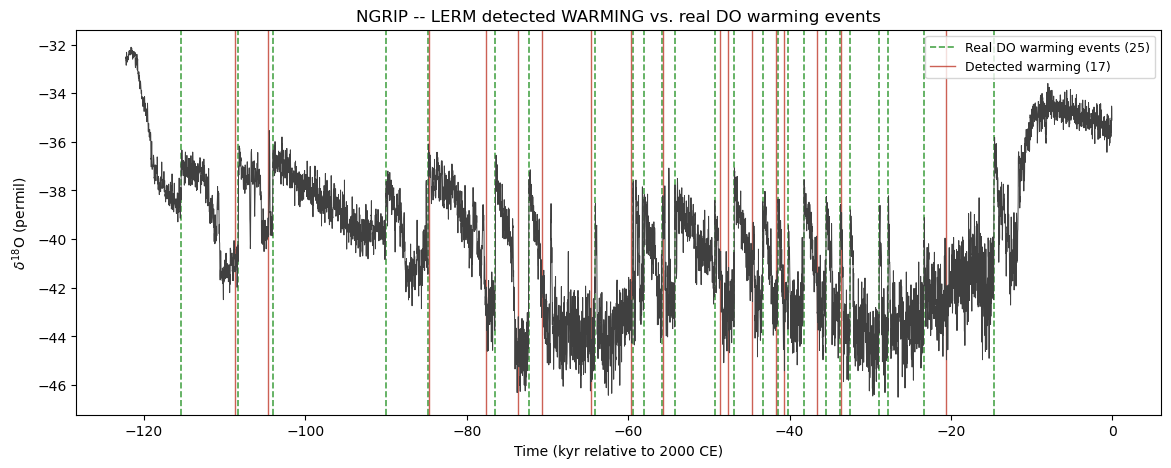

In [13]:
fwd_time = -ngrip_series.time[::-1]
fwd_value = ngrip_series.value[::-1]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(fwd_time, fwd_value, color="0.25", lw=0.7)
for k, t in enumerate(do_gt_times):
    ax.axvline(t, color="green", ls="--", lw=1.2, alpha=0.7, zorder=0, label=f"Real DO warming events ({len(do_gt_times)})" if k == 0 else None)
for k, t in enumerate(lerm_ngrip_det):
    ax.axvline(t, color="#c0392b", lw=1.0, alpha=0.8, zorder=1, label=f"Detected warming ({len(lerm_ngrip_det)})" if k == 0 else None)
ax.set_xlabel("Time (kyr relative to 2000 CE)")
ax.set_ylabel(r"$\delta^{18}$O (permil)")
ax.set_title("NGRIP -- LERM detected WARMING vs. real DO warming events")
ax.legend(loc="upper right", fontsize=9)
plt.show()

In [14]:
def _means(df):
    return [df['precision_warming'].mean(), df['recall_warming'].mean(), df['f1_warming'].mean()]

lerm_ngrip_comparison = pd.DataFrame({
    'LERM train': _means(lerm_train_df),
    'LERM validation': _means(lerm_val_df),
    'LERM test': _means(lerm_test_df) if lerm_test_df is not None else [np.nan] * 3,
    'LERM NGRIP (standardized)': [lerm_ngrip_metrics.precision, lerm_ngrip_metrics.recall, lerm_ngrip_metrics.f1_score],
}, index=['precision_warming', 'recall_warming', 'f1_warming']).dropna(axis=1, how='all')
lerm_ngrip_comparison

,LERM train,LERM validation,LERM test,LERM NGRIP (standardized)
precision_warming,0.303317,0.308753,0.305604,0.411765
recall_warming,0.231102,0.222212,0.228532,0.280000
f1_warming,0.244619,0.241922,0.254615,0.333333
